# 05 — Evaluasi Model

Evaluasi rinci model Random Forest pada data uji (904 ulasan):

- Laporan klasifikasi (precision, recall, F1 per kelas).
- *Confusion matrix* untuk model default & tuning.
- Kurva **ROC** dan nilai **AUC-ROC**.
- *Feature importance* (kata paling berpengaruh).
- Rekap perbandingan default vs tuning (menjawab **RQ2** dan **RQ3**).

Input : `data/processed/prediksi_test.csv`, `model/*.joblib`  
Output: gambar di `model/gambar/`

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_curve,
)

sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

DATA_PROCESSED = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "model"
GAMBAR = MODEL_DIR / "gambar"
GAMBAR.mkdir(parents=True, exist_ok=True)

pred = pd.read_csv(DATA_PROCESSED / "prediksi_test.csv")
tfidf = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")
rf_default = joblib.load(MODEL_DIR / "random_forest_default.joblib")
rf_tuned = joblib.load(MODEL_DIR / "random_forest_tuned.joblib")

y_true = pred["label"].values
p_default, p_tuned = pred["proba_default"].values, pred["proba_tuned"].values
y_default, y_tuned = pred["pred_default"].values, pred["pred_tuned"].values
print("Jumlah data uji:", len(pred))
print("Distribusi nyata:", dict(pred["label"].value_counts().sort_index()))

Jumlah data uji: 904
Distribusi nyata: {0: np.int64(395), 1: np.int64(509)}


In [2]:
for nama, yp in [("Default", y_default), ("Tuning", y_tuned)]:
    print(f"===== Laporan Klasifikasi — RF {nama} =====")
    print(classification_report(y_true, yp, target_names=["negatif", "positif"], digits=4))
    print()

===== Laporan Klasifikasi — RF Default =====
              precision    recall  f1-score   support

     negatif     0.8594    0.9443    0.8999       395
     positif     0.9532    0.8802    0.9152       509

    accuracy                         0.9082       904
   macro avg     0.9063    0.9122    0.9075       904
weighted avg     0.9122    0.9082    0.9085       904


===== Laporan Klasifikasi — RF Tuning =====
              precision    recall  f1-score   support

     negatif     0.8585    0.9367    0.8959       395
     positif     0.9471    0.8802    0.9124       509

    accuracy                         0.9049       904
   macro avg     0.9028    0.9084    0.9042       904
weighted avg     0.9084    0.9049    0.9052       904




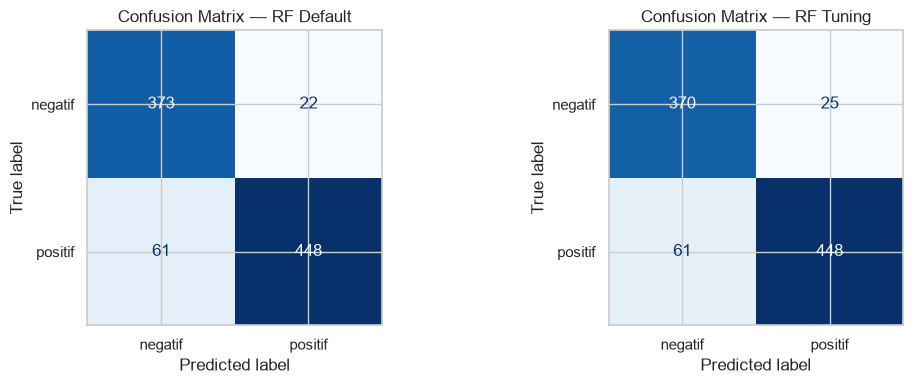

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nama, yp) in zip(axes, [("Default", y_default), ("Tuning", y_tuned)]):
    cm = confusion_matrix(y_true, yp)
    ConfusionMatrixDisplay(cm, display_labels=["negatif", "positif"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"Confusion Matrix — RF {nama}")
plt.tight_layout()
plt.savefig(GAMBAR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

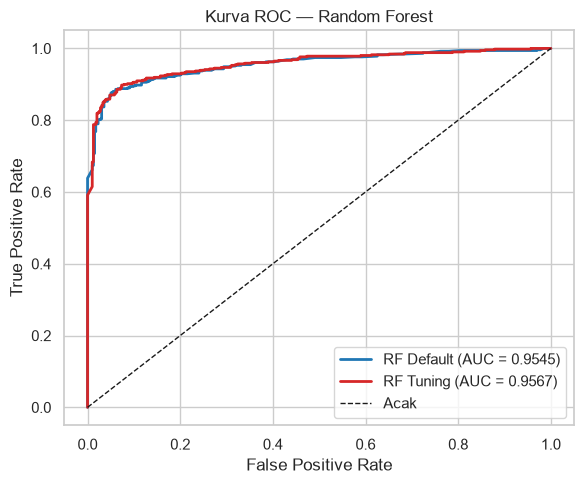

In [4]:
plt.figure(figsize=(6, 5))
for nama, p, warna in [("Default", p_default, "#1f77b4"), ("Tuning", p_tuned, "#d62728")]:
    fpr, tpr, _ = roc_curve(y_true, p)
    plt.plot(fpr, tpr, color=warna, lw=2, label=f"RF {nama} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC — Random Forest")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(GAMBAR / "kurva_roc.png", dpi=150, bbox_inches="tight")
plt.show()

   fitur  importance
   tidak    0.045533
aplikasi    0.024324
   error    0.018795
   tiket    0.014831
  lambat    0.014344
  sering    0.012263
   mudah    0.012098
   bagus    0.010980
   sulit    0.009844
   jelek    0.009696
     mau    0.009299
   malah    0.008819
  sangat    0.008644
 padahal    0.007307
   bantu    0.006488
  jadwal    0.006464
  banyak    0.005893
     nya    0.005878
  update    0.005768
     bug    0.005699


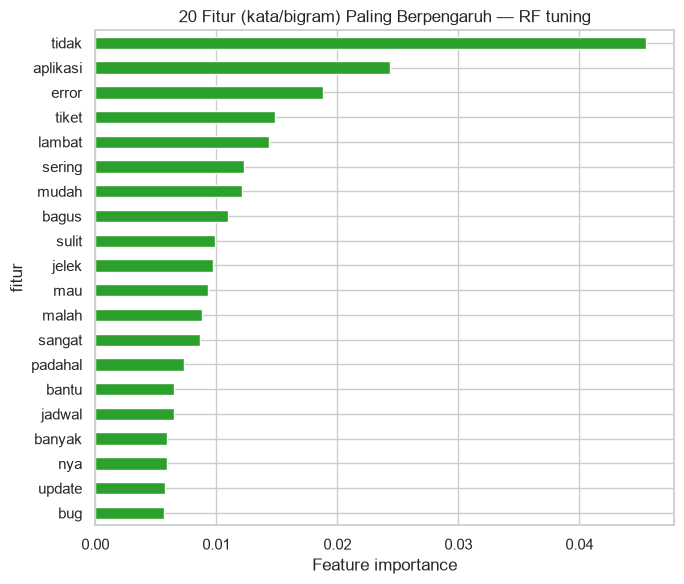

In [5]:
fitur = tfidf.get_feature_names_out()
imp = rf_tuned.feature_importances_
idx = np.argsort(imp)[::-1][:20]

top = pd.DataFrame({"fitur": fitur[idx], "importance": imp[idx]})
print(top.to_string(index=False))

ax = top.sort_values("importance").plot(
    kind="barh", x="fitur", y="importance", legend=False,
    figsize=(7, 6), color="#2ca02c",
)
ax.set_title("20 Fitur (kata/bigram) Paling Berpengaruh — RF tuning")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.savefig(GAMBAR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

            akurasi  precision  recall      f1     auc
RF default   0.9082     0.9532  0.8802  0.9152  0.9545
RF tuning    0.9049     0.9471  0.8802  0.9124  0.9567


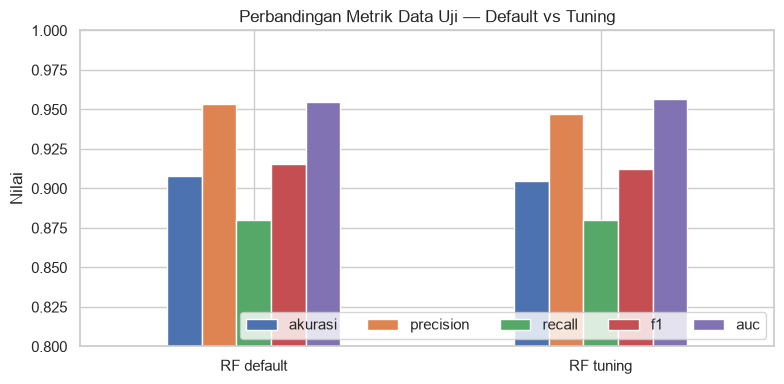

In [6]:
def metrik(yp, p):
    return {
        "akurasi": accuracy_score(y_true, yp),
        "precision": precision_score(y_true, yp),
        "recall": recall_score(y_true, yp),
        "f1": f1_score(y_true, yp),
        "auc": auc(*roc_curve(y_true, p)[:2]),
    }

rekap = pd.DataFrame({
    "RF default": metrik(y_default, p_default),
    "RF tuning": metrik(y_tuned, p_tuned),
}).T
print(rekap.round(4).to_string())
rekap.round(4).to_csv(MODEL_DIR / "rekap_evaluasi_uji.csv")

rekap.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Perbandingan Metrik Data Uji — Default vs Tuning")
plt.ylabel("Nilai")
plt.ylim(0.8, 1.0)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.savefig(GAMBAR / "perbandingan_metrik.png", dpi=150, bbox_inches="tight")
plt.show()

## Kesimpulan Singkat

- **RQ1:** Random Forest dengan fitur TF-IDF (unigram+bigram) berhasil diterapkan untuk
  klasifikasi sentimen biner ulasan Access by KAI.
- **RQ2:** Pada data uji, model mencapai akurasi ≈ 0,90, precision ≈ 0,95,
  recall ≈ 0,88, F1 ≈ 0,91, dan AUC ≈ 0,95.
- **RQ3:** Tuning hyperparameter (GridSearchCV) memberi perubahan kecil; model default
  sedikit lebih tinggi pada akurasi/F1, sedangkan model hasil tuning sedikit lebih baik
  pada AUC. Dengan demikian, pada kasus ini **parameter default Random Forest sudah
  mendekati optimal** di dalam ruang pencarian yang diuji.

> Angka pasti mengacu pada keluaran sel di atas dan berkas
> `model/rekap_evaluasi_uji.csv`.